In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path().resolve().parents[0]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
    
    

from src.config import PROCESSED_DATA_DIR
from src.utils.plots import save_figure, style_plot, create_figure, add_bar_labels, add_source, YOUTUBE_RED, save_table, interpret_eta_squared, DARK_RED
import pandas as pd

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/duration-group-distribution.png


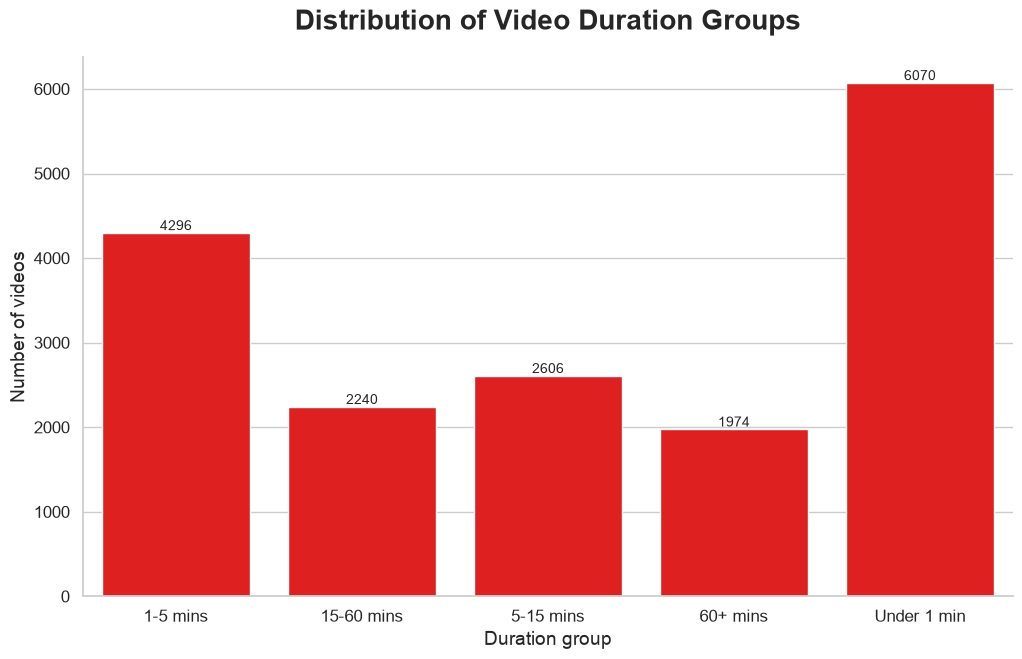

duration_group
Under 1 min    6070
1-5 mins       4296
5-15 mins      2606
15-60 mins     2240
60+ mins       1974
Name: count, dtype: int64


<Figure size 640x480 with 0 Axes>

In [5]:
df = pd.read_csv(PROCESSED_DATA_DIR / "youtube_clean.csv")

fig, ax = create_figure()

sns.countplot(
    data=df,
    x="duration_group",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Duration group",
    ylabel="Number of videos",
    title="Distribution of Video Duration Groups"
)

add_bar_labels(ax)

save_figure(
    fig=fig,
    filename="q3/duration-group-distribution.png"
)

plt.show()
plt.clf()

print(df["duration_group"].value_counts())

findfont: Failed to find font weight semibold, now using 700.


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/duration-group-visibility.png


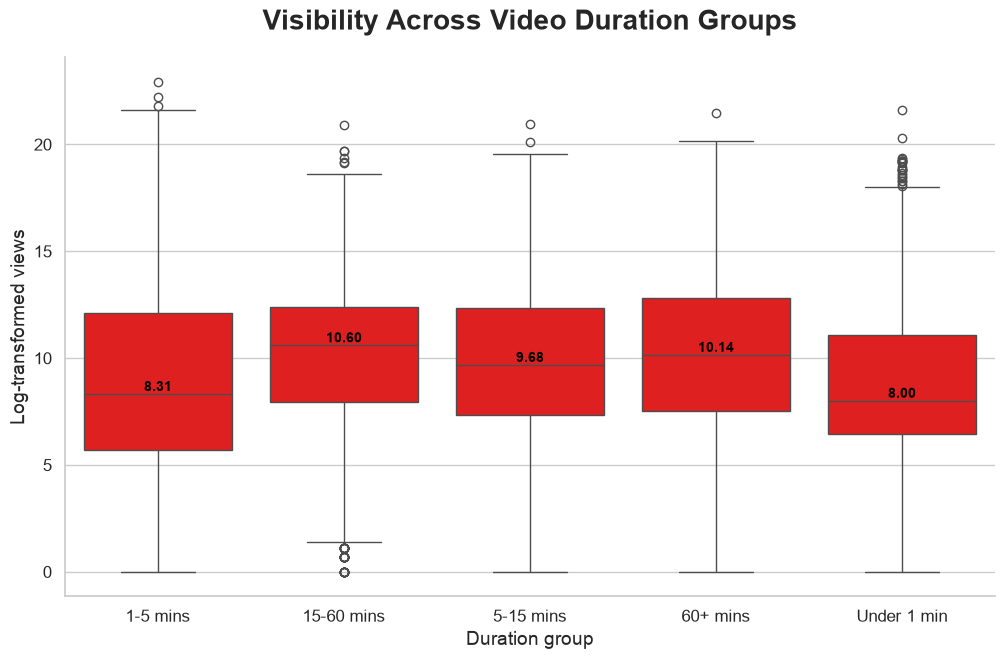

In [6]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="duration_group",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

# Overlay numeric median labels above each box
medians = df.groupby("duration_group")["log_views"].median()
for i, median in enumerate(medians):
    ax.text(
        x=i, 
        y=median + 0.15,  # Slightly above the median line
        s=f"{median:.2f}", 
        horizontalalignment="center", 
        size=10, 
        color="black", 
        weight="semibold"
    )

style_plot(
    ax=ax,
    xlabel="Duration group",
    ylabel="Log-transformed views",
    title="Visibility Across Video Duration Groups"
)

save_figure(
    fig=fig,
    filename="q3/duration-group-visibility.png"
)

plt.show()
plt.close(fig)

In [ ]:
stats = df.groupby("duration_group")["log_views"].describe()
print(stats[["count", "50%", "25%", "75%", "min", "max"]])

                 count        50%       25%        75%  min        max
duration_group                                                        
1-5 mins        4296.0   8.312855  5.722767  12.114163  0.0  22.929917
15-60 mins      2240.0  10.595083  7.928578  12.415794  0.0  20.919266
5-15 mins       2606.0   9.677082  7.337750  12.356565  0.0  20.967105
60+ mins        1974.0  10.144202  7.540611  12.809521  0.0  21.487002
Under 1 min     6070.0   8.000014  6.446116  11.069384  0.0  21.615661


In [10]:
# test if video duration significantly influence views
from scipy.stats import kruskal

groups = [
    group["log_views"].dropna()
    for _, group in df.groupby("duration_group")
]

statistic, p_value = kruskal(*groups)

print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")

print('----------------')
# epsilon-squared.
n = len(df)
k = df["duration_group"].nunique()

epsilon_squared = (
    statistic - k + 1
) / (n - k)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

Kruskal-Wallis H statistic: 498.4275
p-value: 0.000000
----------------
Epsilon-squared: 0.0287


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/category-visibility.png


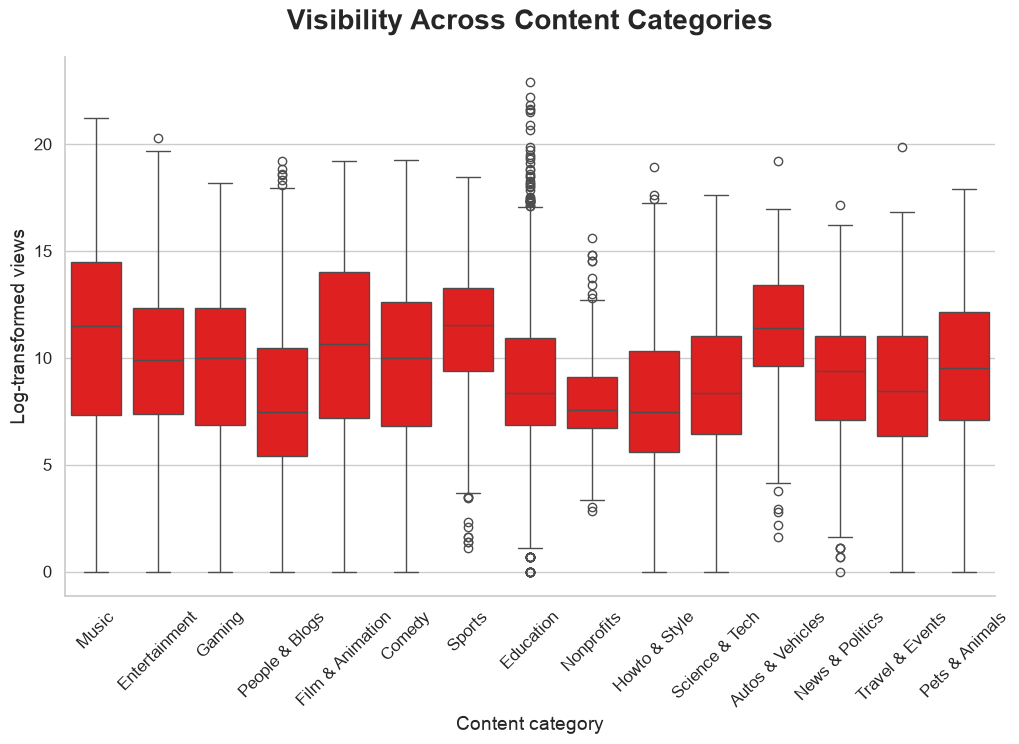

<Figure size 640x480 with 0 Axes>

In [16]:
# content categoried

fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="category_name",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Content category",
    ylabel="Log-transformed views",
    title="Visibility Across Content Categories"
)

ax.tick_params(axis="x", rotation=45)

save_figure(
    fig=fig,
    filename="q3/category-visibility.png"
)

plt.show()
plt.clf()

In [15]:
stats = df.groupby("category_name")["log_views"].describe()
print(stats[["count", "50%", "25%", "75%", "min", "max"]])

                   count        50%       25%        75%       min        max
category_name                                                                
Autos & Vehicles   233.0  11.398704  9.624897  13.427830  1.609438  19.211475
Comedy             244.0   9.972123  6.833411  12.621326  0.000000  19.249683
Education         1185.0   8.360539  6.843750  10.933875  0.000000  22.929917
Entertainment     3269.0   9.907878  7.380256  12.333494  0.000000  20.306457
Film & Animation   741.0  10.656765  7.190676  14.014002  0.000000  19.229570
Gaming             999.0   9.986725  6.862757  12.355227  0.000000  18.207168
Howto & Style      216.0   7.450628  5.595162  10.317791  0.000000  18.946946
Music             1949.0  11.504440  7.317212  14.500411  0.000000  21.232226
News & Politics    482.0   9.401440  7.079415  11.044057  0.000000  17.150723
Nonprofits          86.0   7.574106  6.696096   9.109862  2.833213  15.588788
People & Blogs    6117.0   7.453562  5.416100  10.443862  0.0000

publication_hour
0      436
1      465
2      360
3      373
4      453
5      530
6      522
7      644
8      590
9      659
10     859
11     998
12     961
13    1005
14    1064
15    1062
16    1084
17    1103
18     873
19     800
20     724
21     664
22     512
23     508
Name: count, dtype: int64
Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/publication-hour-distribution.png


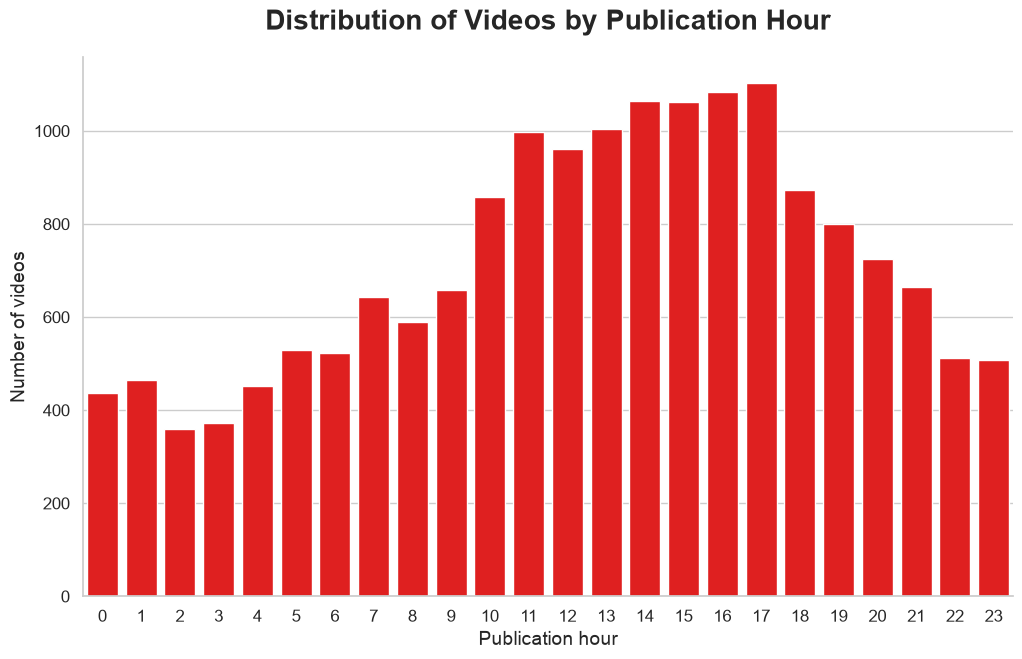

<Figure size 640x480 with 0 Axes>

In [19]:
# views and publication time
df["published_at"] = pd.to_datetime(df["published_at"])

df["publication_hour"] = df["published_at"].dt.hour

print(df["publication_hour"].value_counts().sort_index())


fig, ax = create_figure()

hour_counts = (
    df["publication_hour"]
    .value_counts()
    .sort_index()
)

sns.barplot(
    x=hour_counts.index,
    y=hour_counts.values,
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication hour",
    ylabel="Number of videos",
    title="Distribution of Videos by Publication Hour"
)

save_figure(
    fig=fig,
    filename="q3/publication-hour-distribution.png"
)

plt.show()
plt.clf()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/publication-hour-visibility.png


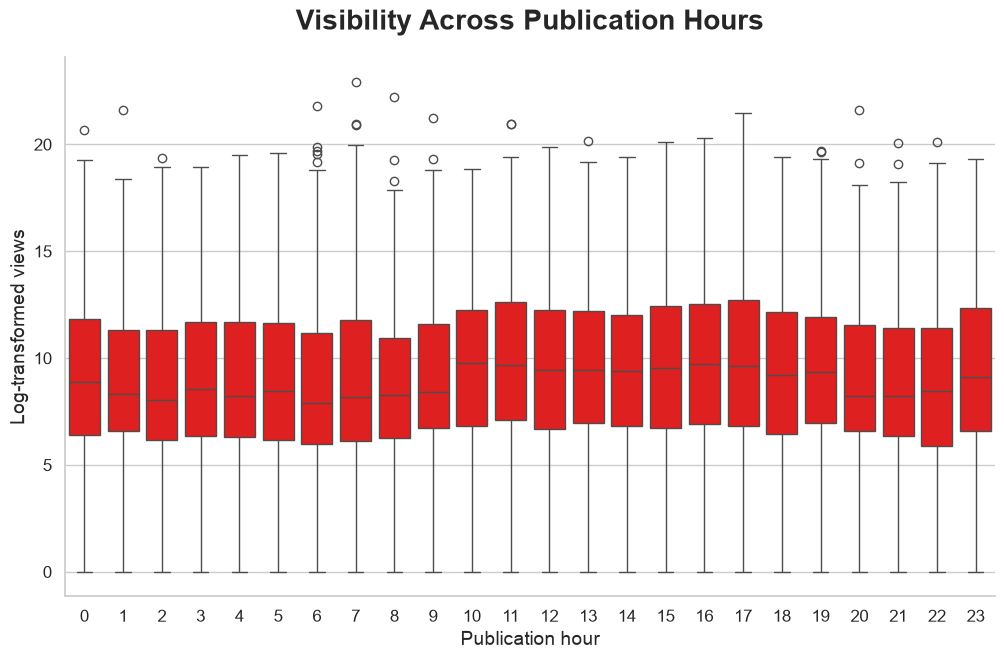

                   count        50%       25%        75%       min        max
category_name                                                                
Autos & Vehicles   233.0  11.398704  9.624897  13.427830  1.609438  19.211475
Comedy             244.0   9.972123  6.833411  12.621326  0.000000  19.249683
Education         1185.0   8.360539  6.843750  10.933875  0.000000  22.929917
Entertainment     3269.0   9.907878  7.380256  12.333494  0.000000  20.306457
Film & Animation   741.0  10.656765  7.190676  14.014002  0.000000  19.229570
Gaming             999.0   9.986725  6.862757  12.355227  0.000000  18.207168
Howto & Style      216.0   7.450628  5.595162  10.317791  0.000000  18.946946
Music             1949.0  11.504440  7.317212  14.500411  0.000000  21.232226
News & Politics    482.0   9.401440  7.079415  11.044057  0.000000  17.150723
Nonprofits          86.0   7.574106  6.696096   9.109862  2.833213  15.588788
People & Blogs    6117.0   7.453562  5.416100  10.443862  0.0000

<Figure size 640x480 with 0 Axes>

In [21]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="publication_hour",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication hour",
    ylabel="Log-transformed views",
    title="Visibility Across Publication Hours"
)

save_figure(
    fig=fig,
    filename="q3/publication-hour-visibility.png"
)

plt.show()
plt.clf()

stats = df.groupby("category_name")["log_views"].describe()
print(stats[["count", "50%", "25%", "75%", "min", "max"]])

In [25]:
def classify_publication_period(hour):
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"


df["publication_period"] = df["publication_hour"].apply(
    classify_publication_period
)

print(df["publication_period"].value_counts())

publication_period_stats = (
    df.groupby("publication_period")["log_views"]
    .describe()
)

print(publication_period_stats)

publication_period
Afternoon    6279
Morning      4272
Evening      4081
Night        2617
Name: count, dtype: int64
                     count      mean       std  min       25%       50%  \
publication_period                                                        
Afternoon           6279.0  9.501032  3.942325  0.0  6.830874  9.522447   
Evening             4081.0  8.949532  3.907769  0.0  6.527958  8.800867   
Morning             4272.0  9.099121  3.916382  0.0  6.598168  8.687526   
Night               2617.0  8.798554  4.010648  0.0  6.343880  8.416710   

                          75%        max  
publication_period                        
Afternoon           12.397048  21.487002  
Evening             11.822628  21.615661  
Morning             11.926828  22.929917  
Night               11.600240  21.627251  


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/publication-period-visibility.png


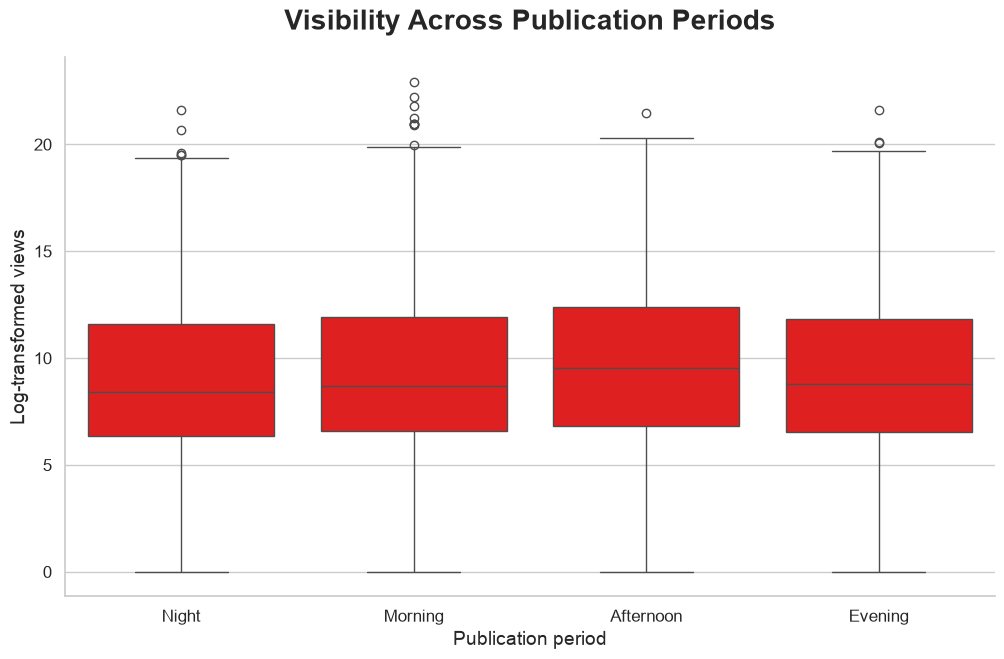

<Figure size 640x480 with 0 Axes>

In [26]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="publication_period",
    y="log_views",
    order=["Night", "Morning", "Afternoon", "Evening"],
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication period",
    ylabel="Log-transformed views",
    title="Visibility Across Publication Periods"
)

save_figure(
    fig=fig,
    filename="q3/publication-period-visibility.png"
)

plt.show()
plt.clf()

In [27]:
# test of significance
from scipy.stats import kruskal

groups = [
    group["log_views"].dropna()
    for _, group in df.groupby("publication_period")
]

statistic, p_value = kruskal(*groups)

print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")


# epsilon square
n = len(df)
k = df["publication_period"].nunique()

epsilon_squared = (statistic - k + 1) / (n - k)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

Kruskal-Wallis H statistic: 87.0716
p-value: 0.000000
Epsilon-squared: 0.0049


In [30]:
# video tag caracteristics
import ast

df["tags_list"] = df["tags"].apply(ast.literal_eval)

df["tag_count"] = df["tags_list"].apply(len)

print(df["tag_count"].describe())



count    17249.000000
mean         7.953157
std         11.220664
min          0.000000
25%          0.000000
50%          0.000000
75%         15.000000
max         97.000000
Name: tag_count, dtype: float64


In [34]:
tag_presence_stats = (
    df.groupby("has_tags")["log_views"]
    .describe()
)

print(tag_presence_stats)

           count       mean       std  min       25%        50%        75%  \
has_tags                                                                     
False     9029.0   8.039947  3.680271  0.0  5.796058   7.613819  10.468290   
True      8220.0  10.399586  3.860581  0.0  7.776220  10.605235  13.168836   

                max  
has_tags             
False     20.206597  
True      22.929917  


/var/folders/w8/kmbm7vc17vb80lb9kj5f78mw0000gn/T/ipykernel_63893/3104414503.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No tags", "Has tags"])


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/tag-presence-visibility.png


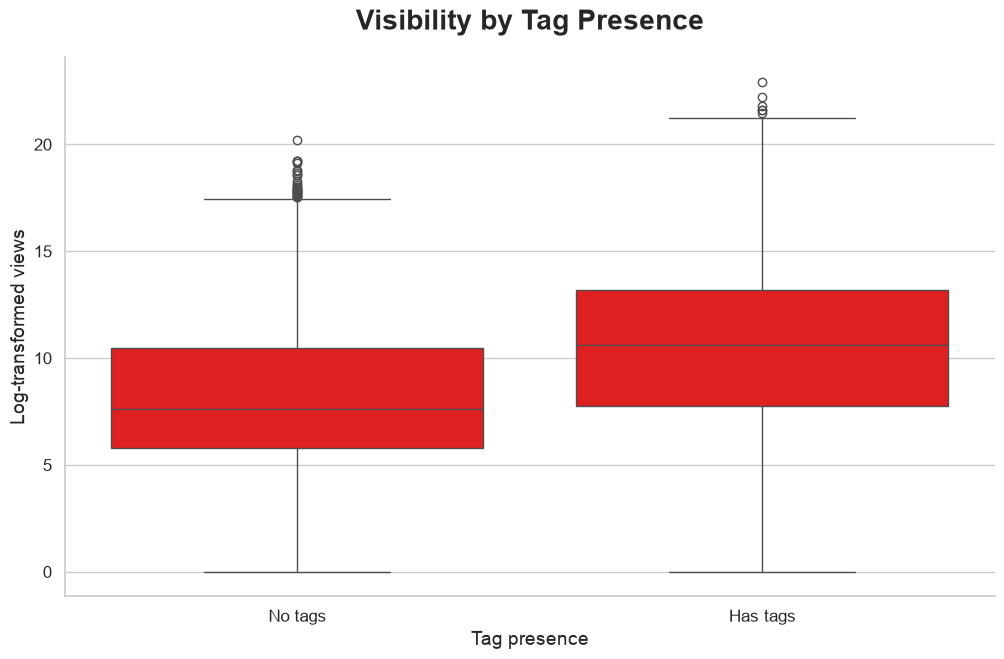

<Figure size 640x480 with 0 Axes>

In [35]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="has_tags",
    y="log_views",
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Tag presence",
    ylabel="Log-transformed views",
    title="Visibility by Tag Presence"
)

ax.set_xticklabels(["No tags", "Has tags"])

save_figure(
    fig=fig,
    filename="q3/tag-presence-visibility.png"
)

plt.show()
plt.clf()

In [47]:
# test if the visibility differs between videos with tags and no tags
from scipy.stats import mannwhitneyu

no_tags = df.loc[
    df["has_tags"] == False,
    "log_views"
]

has_tags = df.loc[
    df["has_tags"] == True,
    "log_views"
]

statistic, p_value = mannwhitneyu(
    no_tags,
    has_tags,
    alternative="two-sided"
)

print(f"Mann-Whitney U statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")

# effect size

from scipy.stats import mannwhitneyu

no_tags = df.loc[
    df["has_tags"] == False,
    "log_views"
]

has_tags = df.loc[
    df["has_tags"] == True,
    "log_views"
]

statistic, p_value = mannwhitneyu(
    no_tags,
    has_tags,
    alternative="two-sided"
)

print(f"Mann-Whitney U statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")

# Rank-biserial correlation
n1 = len(no_tags)
n2 = len(has_tags)

rank_biserial = 1 - (2 * statistic) / (n1 * n2) # type: ignore

print("------------")
print(f"Rank-biserial correlation: {rank_biserial:.4f}")

Mann-Whitney U statistic: 23980353.0000
p-value: 0.000000
Mann-Whitney U statistic: 23980353.0000
p-value: 0.000000
------------
Rank-biserial correlation: 0.3538


In [48]:
df.head()

,video_id,title,description,published_at,category_id,tags,duration,channel_id,channel_title,views,...,is_short,duration_group,is_viral,tag_count,has_tags,category_name,publication_hour,publication_period,tags_list,publication_day
0,ELkyDvO-j6Q,treat u right,Provided to YouTube by EMPIRE Distribution\n\n...,2026-07-02 22:11:35+00:00,10,"['FOLA', 'Ayra Starr', 'treat u right']",PT2M58S,UC4mHpkf_26sEWN8M5PMpV_w,FOLA - Topic,120661,...,0,1-5 mins,0,3,True,Music,22,Evening,"[FOLA, Ayra Starr, treat u right]",Thursday
1,hMlHf-YXVUM,ALAKADA GEN Z 3 (Official Trailer) | Latest Ni...,ALAKADA GEN Z 3 Official Trailer is here! 🎬😂 \...,2026-07-05 17:00:39+00:00,24,"['Alakada Gen Z 3', 'Alakada Gen Z 3 trailer',...",PT2M33S,UCoSnFVOBlcdgjSUETGd65kA,Toyin Abraham TV,69067,...,0,1-5 mins,0,23,True,Entertainment,17,Afternoon,"[Alakada Gen Z 3, Alakada Gen Z 3 trailer, Ala...",Sunday
2,BaO6Dnxquv8,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,2026-07-05 20:06:24+00:00,20,"['gta 5 live', 'gta v live stream', 'gta 5 gam...",PT31M8S,UC9OTne2HnCn_kkyx8NodI-g,Pixel Hunters,14163447,...,0,15-60 mins,1,25,True,Gaming,20,Evening,"[gta 5 live, gta v live stream, gta 5 gameplay...",Sunday
3,KkDHSWq7XGw,Jorja Smith - Alive feat. Wizkid,Jorja Smith - Alive feat. Wizkid - Out now: ht...,2026-07-02 16:00:27+00:00,10,"['jorja smith', 'alive', 'wizkid', 'what are t...",PT3M31S,UCHA6dVPvxRdLQ5Uu-uX3MLw,Jorja Smith,952264,...,0,1-5 mins,0,5,True,Music,16,Afternoon,"[jorja smith, alive, wizkid, what are the odds...",Thursday
4,DVHPZ36Sav8,IYE Latest Yoruba Movie 2026 l Official Traile...,Some homes don’t let you leave…\nAnd if you do...,2026-06-29 17:00:24+00:00,22,[],PT1M28S,UCi00_82Wh1q_rm2Yz8m7GIA,THE DAMILOLA ONI TV,72623,...,0,1-5 mins,0,0,False,People & Blogs,17,Afternoon,[],Monday


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/discovery-pathway-distribution.png


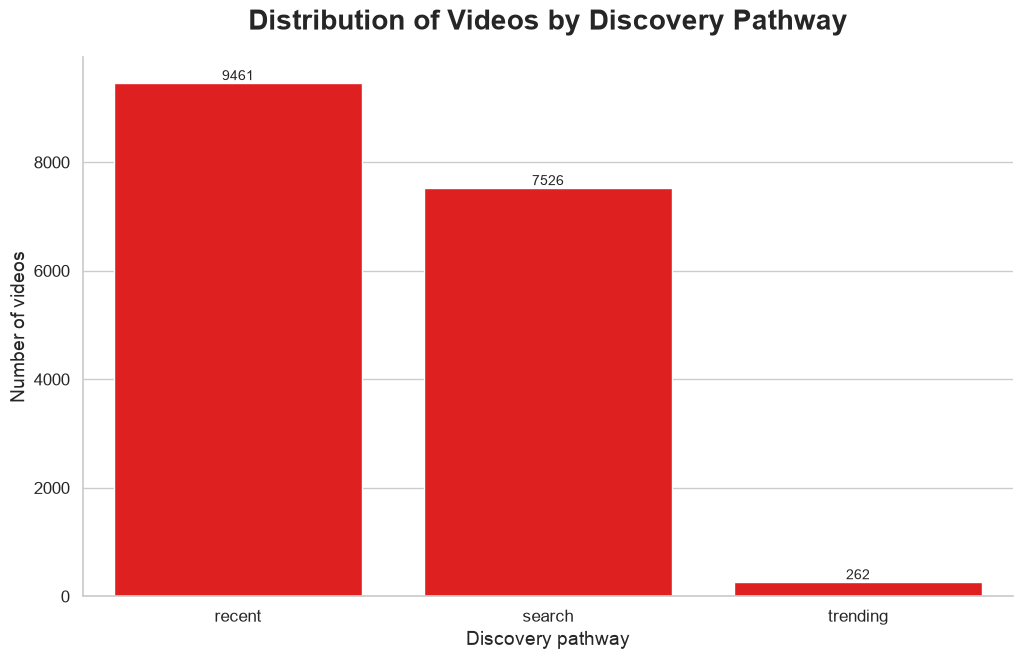

<Figure size 640x480 with 0 Axes>

In [38]:
fig, ax = create_figure()

sns.countplot(
    data=df,
    x="discovery_source",
    order=df["discovery_source"].value_counts().index,
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Discovery pathway",
    ylabel="Number of videos",
    title="Distribution of Videos by Discovery Pathway"
)

add_bar_labels(ax)

save_figure(
    fig=fig,
    filename="q2/discovery-pathway-distribution.png"
)

plt.show()
plt.clf()

In [39]:
discovery_visibility_stats = (
    df.groupby("discovery_source")["log_views"]
    .describe()
)

print(discovery_visibility_stats)

                   count       mean       std       min        25%        50%  \
discovery_source                                                                
recent            9461.0   7.423236  3.435354  0.000000   5.278115   7.253470   
search            7526.0  11.234638  3.496119  0.000000   8.630209  11.438320   
trending           262.0  12.573106  2.080701  6.308098  11.023094  12.508631   

                        75%        max  
discovery_source                        
recent             9.729848  21.615661  
search            13.734190  22.929917  
trending          13.928099  18.207168  


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/discovery-pathway-visibility.png


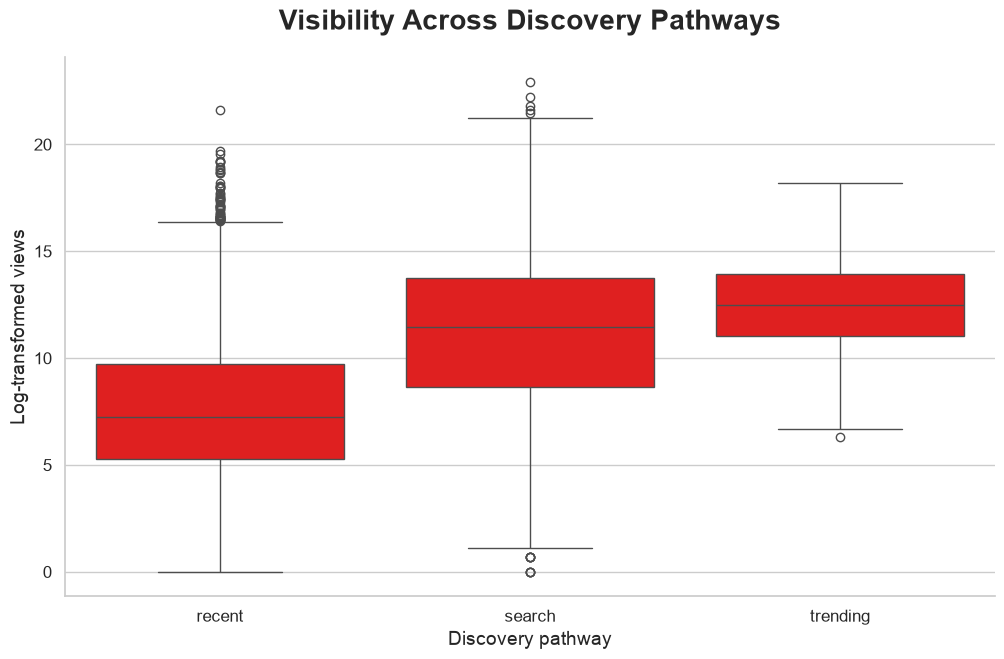

<Figure size 640x480 with 0 Axes>

In [40]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="discovery_source",
    y="log_views",
    order=["recent", "search", "trending"],
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Discovery pathway",
    ylabel="Log-transformed views",
    title="Visibility Across Discovery Pathways"
)

save_figure(
    fig=fig,
    filename="q2/discovery-pathway-visibility.png"
)

plt.show()
plt.clf()

In [41]:
# test of significance
from scipy.stats import kruskal

groups = [
    group["log_views"].dropna()
    for _, group in df.groupby("discovery_source")
]

statistic, p_value = kruskal(*groups)

print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")

print('---------------------')

n = len(df)
k = df["discovery_source"].nunique()

epsilon_squared = (statistic - k + 1) / (n - k)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

Kruskal-Wallis H statistic: 4221.7511
p-value: 0.000000
---------------------
Epsilon-squared: 0.2447


Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q3/publication-day-distribution.png


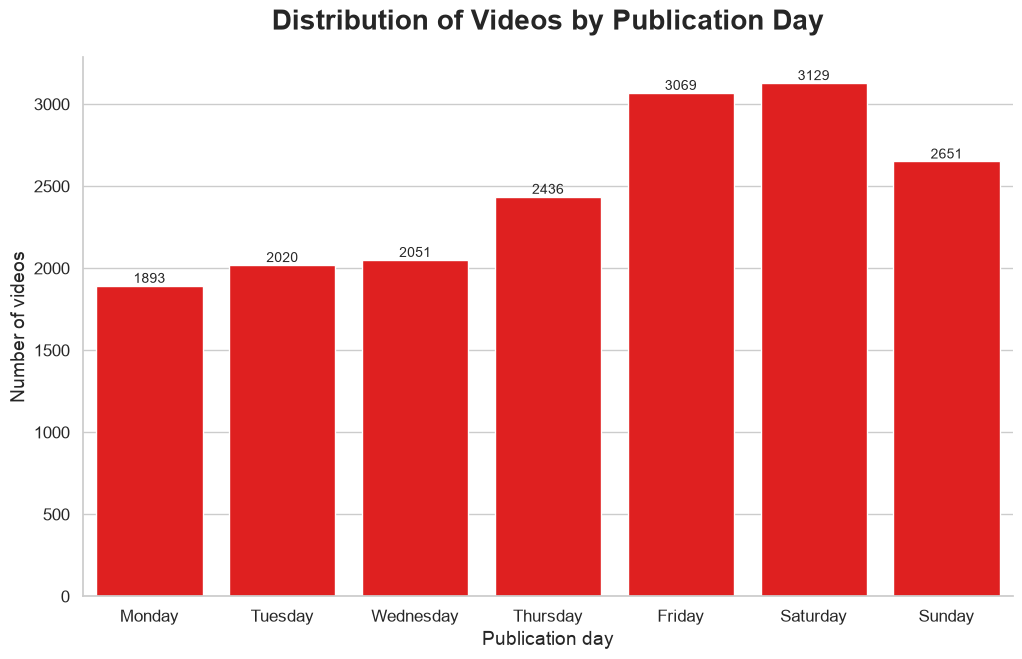

<Figure size 640x480 with 0 Axes>

In [43]:
# day of the week as a characteristics of visibility
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

fig, ax = create_figure()

sns.countplot(
    data=df,
    x="publication_day",
    order=day_order,
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication day",
    ylabel="Number of videos",
    title="Distribution of Videos by Publication Day"
)

add_bar_labels(ax)

save_figure(
    fig=fig,
    filename="q3/publication-day-distribution.png"
)

plt.show()
plt.clf()

In [44]:
publication_day_stats = (
    df.groupby("publication_day")["log_views"]
    .describe()
    .reindex(day_order)
)

print(publication_day_stats)

                  count      mean       std  min       25%        50%  \
publication_day                                                         
Monday           1893.0  9.198013  4.003246  0.0  6.467699   8.969923   
Tuesday          2020.0  9.656587  3.930397  0.0  6.923382   9.836321   
Wednesday        2051.0  9.980714  3.710368  0.0  7.469360  10.081550   
Thursday         2436.0  9.294112  4.058417  0.0  6.638240   9.386264   
Friday           3069.0  9.131951  4.052514  0.0  6.605298   8.938663   
Saturday         3129.0  8.439095  3.851102  0.0  6.212606   8.099554   
Sunday           2651.0  8.908468  3.806403  0.0  6.638568   8.446771   

                       75%        max  
publication_day                        
Monday           11.996986  21.232226  
Tuesday          12.628300  22.230910  
Wednesday        12.645954  21.627251  
Thursday         12.262148  22.929917  
Friday           12.006829  21.615661  
Saturday         11.014736  20.655354  
Sunday           11.76

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/publication-day-visibility.png


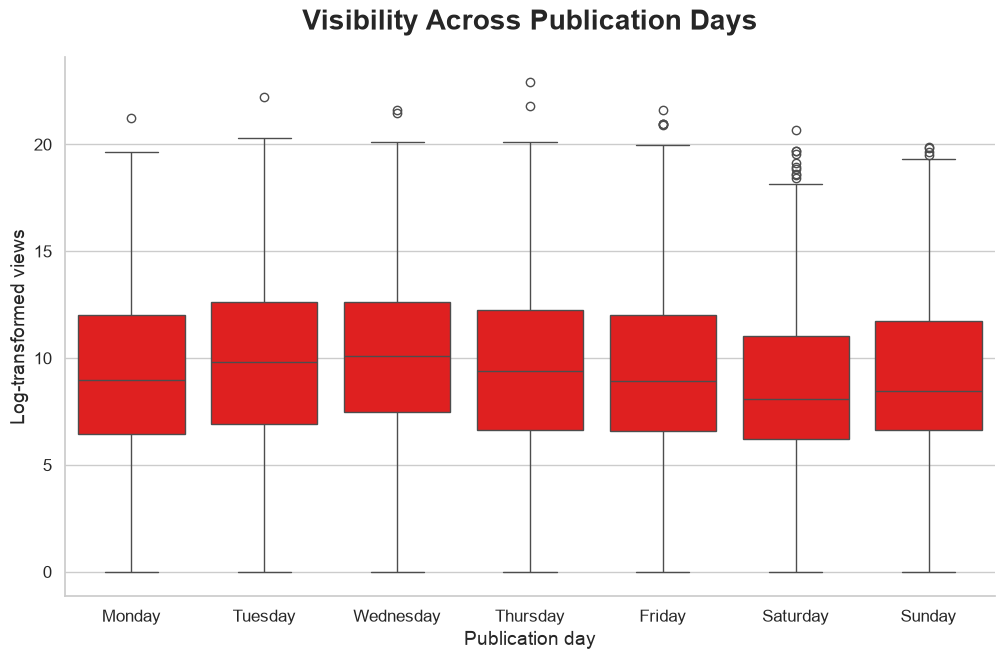

<Figure size 640x480 with 0 Axes>

In [45]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="publication_day",
    y="log_views",
    order=day_order,
    color=YOUTUBE_RED,
    ax=ax
)

style_plot(
    ax=ax,
    xlabel="Publication day",
    ylabel="Log-transformed views",
    title="Visibility Across Publication Days"
)

save_figure(
    fig=fig,
    filename="q2/publication-day-visibility.png"
)

plt.show()
plt.clf()

In [46]:
# test of statistical importance
groups = [
    group["log_views"].dropna()
    for _, group in df.groupby("publication_day")
]

statistic, p_value = kruskal(*groups)

print(f"Kruskal-Wallis H statistic: {statistic:.4f}")
print(f"p-value: {p_value:.6f}")

print('------------')
n = len(df)
k = df["publication_day"].nunique()

epsilon_squared = (statistic - k + 1) / (n - k)

print(f"Epsilon-squared: {epsilon_squared:.4f}")

Kruskal-Wallis H statistic: 247.9944
p-value: 0.000000
------------
Epsilon-squared: 0.0140


In [49]:
df.head()

,video_id,title,description,published_at,category_id,tags,duration,channel_id,channel_title,views,...,is_short,duration_group,is_viral,tag_count,has_tags,category_name,publication_hour,publication_period,tags_list,publication_day
0,ELkyDvO-j6Q,treat u right,Provided to YouTube by EMPIRE Distribution\n\n...,2026-07-02 22:11:35+00:00,10,"['FOLA', 'Ayra Starr', 'treat u right']",PT2M58S,UC4mHpkf_26sEWN8M5PMpV_w,FOLA - Topic,120661,...,0,1-5 mins,0,3,True,Music,22,Evening,"[FOLA, Ayra Starr, treat u right]",Thursday
1,hMlHf-YXVUM,ALAKADA GEN Z 3 (Official Trailer) | Latest Ni...,ALAKADA GEN Z 3 Official Trailer is here! 🎬😂 \...,2026-07-05 17:00:39+00:00,24,"['Alakada Gen Z 3', 'Alakada Gen Z 3 trailer',...",PT2M33S,UCoSnFVOBlcdgjSUETGd65kA,Toyin Abraham TV,69067,...,0,1-5 mins,0,23,True,Entertainment,17,Afternoon,"[Alakada Gen Z 3, Alakada Gen Z 3 trailer, Ala...",Sunday
2,BaO6Dnxquv8,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,2026-07-05 20:06:24+00:00,20,"['gta 5 live', 'gta v live stream', 'gta 5 gam...",PT31M8S,UC9OTne2HnCn_kkyx8NodI-g,Pixel Hunters,14163447,...,0,15-60 mins,1,25,True,Gaming,20,Evening,"[gta 5 live, gta v live stream, gta 5 gameplay...",Sunday
3,KkDHSWq7XGw,Jorja Smith - Alive feat. Wizkid,Jorja Smith - Alive feat. Wizkid - Out now: ht...,2026-07-02 16:00:27+00:00,10,"['jorja smith', 'alive', 'wizkid', 'what are t...",PT3M31S,UCHA6dVPvxRdLQ5Uu-uX3MLw,Jorja Smith,952264,...,0,1-5 mins,0,5,True,Music,16,Afternoon,"[jorja smith, alive, wizkid, what are the odds...",Thursday
4,DVHPZ36Sav8,IYE Latest Yoruba Movie 2026 l Official Traile...,Some homes don’t let you leave…\nAnd if you do...,2026-06-29 17:00:24+00:00,22,[],PT1M28S,UCi00_82Wh1q_rm2Yz8m7GIA,THE DAMILOLA ONI TV,72623,...,0,1-5 mins,0,0,False,People & Blogs,17,Afternoon,[],Monday
